In [1]:
import marimo as mo

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from kaggle_api import fetch_dataset

df_train, df_test = fetch_dataset()

✅ data loaded!


# model overview

predictors:

- categorical - $x_4, x_5, x_{10}$
- create new predictor $x_{11} := \mathbb{1} \{x_1 >= 0\}$

model type: manual regression / classification tree

In this model, we take the categorical predictors and calculate the positive response probability as the outer-product proportions:

$$
\Pr \left(Y = 1 \mid X_4 = x_4, X_5 = x_5, X_{10} = x_{10}, X_{11} = x_{11}\right)
    \approx \frac
        {\text{count}_{\text{train}} \left(Y = 1, X_4 = x_4, X_5 = x_5, X_{10} = x_{10}, X_{11} = x_{11}\right)}
        {\text{count}_{\text{train}} \left(X_4 = x_4, X_5 = x_5, X_{10} = x_{10}, X_{11} = x_{11}\right)}
$$

In [4]:
df_train["x11"] = (df_train.x1 >= 0).astype(np.int8)
df_test["x11"] = (df_test.x1 >= 0).astype(np.int8)

active_pred_names = "x4 x5 x10 x11".split()

In [5]:
model_weights = (
    df_train.loc[df_train.Y == 1, active_pred_names].value_counts()
    / df_train[active_pred_names].value_counts()
)

prediction_probs = model_weights[
    (row for i, row in df_test[active_pred_names].iterrows())
]
prediction_probs.name = "prediction probabilities"

display(df_test.loc[15001:15005, active_pred_names])
display(prediction_probs.index[0:5])

prediction_probs.index = df_test.index

,x4,x5,x10,x11
ID,,,,
15001,0,0,3,0
15002,1,1,3,1
15003,0,0,1,1
15004,1,1,0,0
15005,1,0,2,0


MultiIndex([(0, 0, 3, 0),
            (1, 1, 3, 1),
            (0, 0, 1, 1),
            (1, 1, 0, 0),
            (1, 0, 2, 0)],
           names=['x4', 'x5', 'x10', 'x11'])

# model assessment

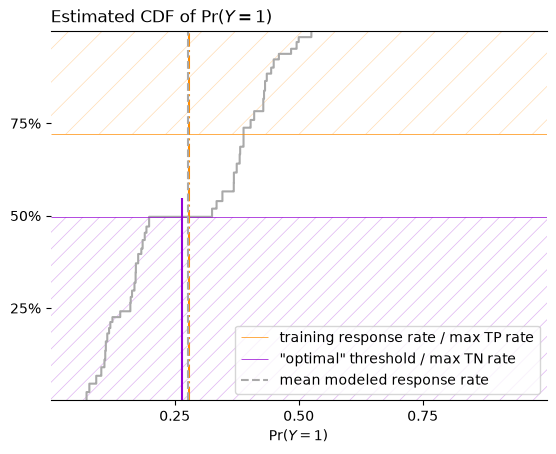

In [6]:
import threshold as th

pos_prediction_count, threshold = th.estimate_optimal_threshold(prediction_probs)

mo.output.append(pos_prediction_count)
mo.output.append(threshold)

mo.output.append(
    th.plot_probs(
        probs=prediction_probs,
        expt_prob=np.mean(df_train.Y.astype(np.int64)),
        threshold=threshold,
        pos_pred_count=pos_prediction_count,
    )
)

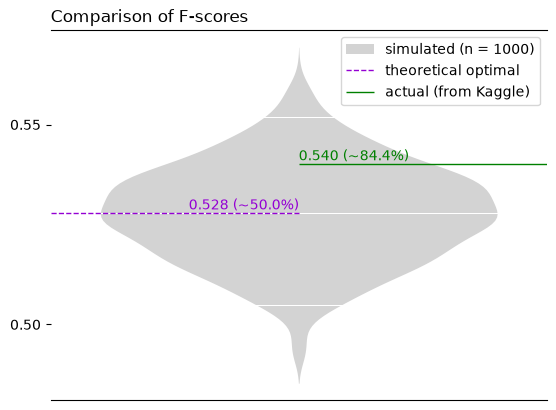

In [10]:
rng = np.random.default_rng(1)

_ = th.plot_f_scores(
    empiricals=th.sample_probable_f_scores(
        rng,
        1000,
        prediction_probs,
        pos_prediction_count,
        report_count=(3 * len(prediction_probs)) // 10,  # reported score uses 30% of the test data
    ),
    calculated=2 * threshold,
    reported=0.54023,
)

## conclusion

- ✅ the modeled average response rate (mostly) matches the training average
- ✅ the reported F-score is within the simulated 95% CI
- the F-score is rather low
- the model is simple -> there's probably not too much that could be misrepresentative about it

# make submission

In [8]:
predictions = prediction_probs.sort_values(ascending=False)
predictions.iloc[0:pos_prediction_count] = 1
predictions.iloc[pos_prediction_count:] = 0
predictions = predictions.astype(np.int8).sort_index()

predictions

ID
15001    0
15002    1
15003    1
15004    0
15005    0
        ..
24996    1
24997    1
24998    0
24999    0
25000    0
Name: prediction probabilities, Length: 10000, dtype: int8

In [9]:
import os.path
import pathlib

submission_filepath = pathlib.Path("./submissions/model1-ba.csv")
print(f"saving submission file to {submission_filepath}")
predictions.to_csv(submission_filepath)

saving submission file to submissions/model1-ba.csv
